## Exercitiul 3

In [5]:
# a)
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

y = np.array([3, 4, 2, 5, 3, 4, 3, 2, 4, 3, 4, 5, 5, 6, 5, 7, 6, 8, 7, 9, 8, 10, 9, 8, 11, 9, 10, 8, 9, 10])
t = np.arange(1, 31)

with pm.Model() as model:
    lambda1 = pm.Exponential('lambda1', lam=0.2)
    lambda2 = pm.Exponential('lambda2', lam=0.2)
    r = pm.Uniform('r', lower=1, upper=30)
    k = pm.Exponential('k', lam=1)
    lam_t = lambda1 + (lambda2 - lambda1) * pm.math.sigmoid(k * (t - r))
    pm.Deterministic('lam_t', lam_t)
    pm.Poisson('y_obs', mu=lam_t, observed=y)
    trace = pm.sample(draws=2000, chains=4, target_accept=0.9, random_seed=42)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [lambda1, lambda2, r, k]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 7 seconds.


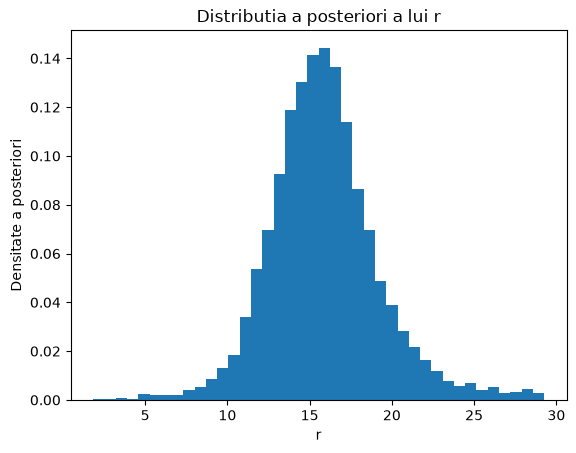

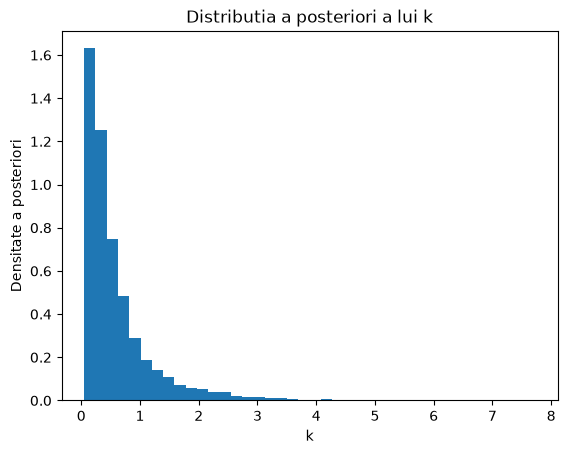

HDI 95% r: (9.199333407654732, 22.759602705116315)
HDI 95% k: (0.04948824262794678, 1.8917334249937976)


In [6]:
# b)
r_samples = trace['posterior']['r'].values.flatten()
k_samples = trace['posterior']['k'].values.flatten()

plt.hist(r_samples, bins=40, density=True)
plt.xlabel('r')
plt.ylabel('Densitate a posteriori')
plt.title('Distributia a posteriori a lui r')
plt.savefig('ex3_posterior_r.png')
plt.show()

plt.hist(k_samples, bins=40, density=True)
plt.xlabel('k')
plt.ylabel('Densitate a posteriori')
plt.title('Distributia a posteriori a lui k')
plt.savefig('ex3_posterior_k.png')
plt.show()

hdi_r = az.hdi(trace['posterior']['r'], prob=0.95)
hdi_k = az.hdi(trace['posterior']['k'], prob=0.95)
print('HDI 95% r:', (hdi_r.sel(ci_bound='lower').item(), hdi_r.sel(ci_bound='upper').item()))
print('HDI 95% k:', (hdi_k.sel(ci_bound='lower').item(), hdi_k.sel(ci_bound='upper').item()))

P(lambda2 > lambda1): 1.0


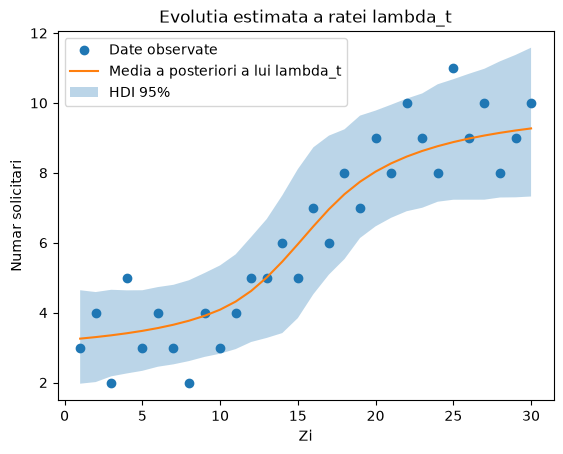

In [7]:
# c)
prob_lambda2_mai_mare = (trace['posterior']['lambda2'] > trace['posterior']['lambda1']).mean().item()
print('P(lambda2 > lambda1):', prob_lambda2_mai_mare)

lam_t_samples = trace['posterior']['lam_t'].values.reshape(-1, len(t))
lam_t_mean = lam_t_samples.mean(axis=0)
lam_t_hdi = az.hdi(trace['posterior']['lam_t'], prob=0.95)
lam_t_low = lam_t_hdi.sel(ci_bound='lower').values
lam_t_high = lam_t_hdi.sel(ci_bound='upper').values

plt.plot(t, y, 'o', label='Date observate')
plt.plot(t, lam_t_mean, label='Media a posteriori a lui lambda_t')
plt.fill_between(t, lam_t_low, lam_t_high, alpha=0.3, label='HDI 95%')
plt.xlabel('Zi')
plt.ylabel('Numar solicitari')
plt.title('Evolutia estimata a ratei lambda_t')
plt.legend()
plt.savefig('ex3_evolutie_lambda.png')
plt.show()

Sampling: [y_new]


Output()

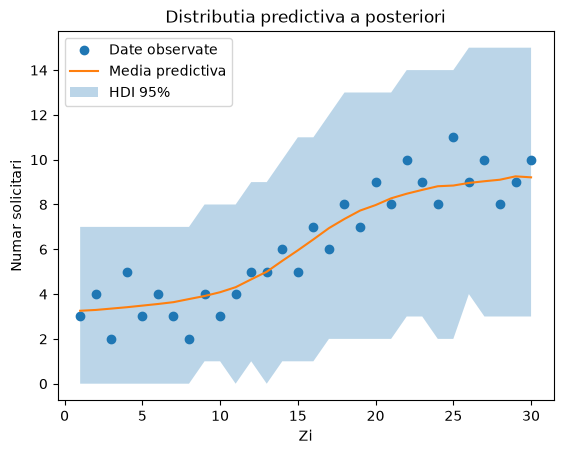

Proportia observatiilor din HDI 95%: 1.0
Eroarea medie absoluta: 0.7566708333333333


In [8]:
# d)
with model:
    y_new = pm.Poisson('y_new', mu=lam_t)
    ppc = pm.sample_posterior_predictive(trace, var_names=['y_new'], random_seed=42)

y_new_samples = ppc['posterior_predictive']['y_new'].values.reshape(-1, len(t))
y_new_mean = y_new_samples.mean(axis=0)
y_new_hdi = az.hdi(ppc['posterior_predictive']['y_new'], prob=0.95)
y_new_low = y_new_hdi.sel(ci_bound='lower').values
y_new_high = y_new_hdi.sel(ci_bound='upper').values

plt.plot(t, y, 'o', label='Date observate')
plt.plot(t, y_new_mean, label='Media predictiva')
plt.fill_between(t, y_new_low, y_new_high, alpha=0.3, label='HDI 95%')
plt.xlabel('Zi')
plt.ylabel('Numar solicitari')
plt.title('Distributia predictiva a posteriori')
plt.legend()
plt.savefig('ex3_predictiv.png')
plt.show()

acoperire = np.mean((y >= y_new_low) & (y <= y_new_high))
print('Proportia observatiilor din HDI 95%:', acoperire)
print('Eroarea medie absoluta:', np.mean(np.abs(y_new_mean - y)))